# 80 % conformal band on demand 30-day-ahead curves

**Question**: at inference, return an *area* around the predicted demand curve, calibrated so the area contains the actual curve on average **80 %** of the time on 2024 test data.

**Recipe**: split conformal on top of the current Wasserstein champion (`Exp5 FoF + closest-curve snap`).

**Why a τ grid in the first place** — the conformal band is derived in *normalised* space: at each of 64 quantile positions `τ ∈ [0.02, 0.98]` of `cumulative_quantity / total_quantity`, we know the conformal half-width `q(τ)` from the calibration set. To display this band in **real MW** on the x-axis, we multiply τ by the *predicted curve's total quantity* per row (the only total we know at inference time).

**This notebook shows** for each example auction:

- **black step** = actual realised curve, on real MW × $/MWh axes
- **red step** = lag-30 baseline curve
- **blue step** = Exp5 point forecast (the curve our model retrieves)
- **blue shaded** = marginal 80 %-coverage band (per-τ, denormalised by the predicted total quantity)
- **orange shaded** = joint 80 %-coverage band (sup-norm, denormalised same way)

In [1]:
import sys
from pathlib import Path
REPO_ROOT = Path('..').resolve()
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from aemo_curves.config import DEFAULT_QUANTITY_GRID
from aemo_curves.models import Lag1Predictor
from experiments.recompute_2024test._loader import load_2024test_split

plt.rcParams['figure.dpi'] = 110
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3

REPO = REPO_ROOT
ALPHA = 0.20
TARGET = 1 - ALPHA            # 0.80
SUMMARY = json.loads((REPO / 'experiments/proposals_top5/band_q_a20.json').read_text())
PREDS = pd.read_pickle(REPO / 'experiments/proposals_top5/band_predictions_a20.pkl')
PREDS['Trading Date'] = pd.to_datetime(PREDS['Trading Date'])
TAU = DEFAULT_QUANTITY_GRID    # 64 points in [0.02, 0.98]

print(f'Target coverage: {TARGET:.0%} (α = {ALPHA})')
print(f'Loaded {len(PREDS):,} test rows')

Target coverage: 80% (α = 0.2)
Loaded 17,568 test rows


## Compute baseline (lag-30) curves and merge

The conformal pickle has actual, predicted, and band columns but **not** the lag-30 baseline. We rebuild it from the cached embeddings using the same `Lag1Predictor(lag_days=30)` that defines our baseline everywhere else.

In [2]:
train, test = load_2024test_split(side='demand')
historical = pd.concat([train, test], ignore_index=True)
base = Lag1Predictor(lag_days=30).fit(train).predict(test, historical)
base['Trading Date'] = pd.to_datetime(base['Trading Date'])
PREDS = PREDS.merge(
    base[['Trading Date', 'Interval Number', 'pred_curve_qty', 'pred_curve_price']]
      .rename(columns={'pred_curve_qty': 'baseline_curve_qty',
                       'pred_curve_price': 'baseline_curve_price'}),
    on=['Trading Date', 'Interval Number'], how='left',
)

# Per-row coverage diagnostics (still in normalised τ-space — the band's natural home)
TRUE     = np.vstack(PREDS['true_embedding'].to_numpy())
PRED     = np.vstack(PREDS['pred_embedding'].to_numpy())
MARG_LO  = np.vstack(PREDS['marginal_band_lower'].to_numpy())
MARG_HI  = np.vstack(PREDS['marginal_band_upper'].to_numpy())
JOINT_LO = np.vstack(PREDS['band_lower'].to_numpy())
JOINT_HI = np.vstack(PREDS['band_upper'].to_numpy())
joint_inside = np.all((TRUE >= JOINT_LO) & (TRUE <= JOINT_HI), axis=1)
marg_frac    = ((TRUE >= MARG_LO) & (TRUE <= MARG_HI)).mean(axis=1)
PREDS['joint_inside'] = joint_inside
PREDS['marg_frac']    = marg_frac
PREDS['pred_total_qty']     = PREDS['pred_curve_qty'].apply(lambda q: float(np.asarray(q)[-1]))
PREDS['true_total_qty']     = PREDS['true_curve_qty'].apply(lambda q: float(np.asarray(q)[-1]))
PREDS['baseline_total_qty'] = PREDS['baseline_curve_qty'].apply(
    lambda q: float(np.asarray(q)[-1]) if q is not None else np.nan)

print('After merge:', PREDS.shape, 'cols:', list(PREDS.columns))
print(f'\nMarginal 80 % band: avg fraction inside = {marg_frac.mean():.4f}')
print(f'Joint sup-norm 80 % band: rows fully inside = {joint_inside.mean():.4f}')
print(f'Total quantity (MW) — true: median {PREDS["true_total_qty"].median():.0f}, p95 {PREDS["true_total_qty"].quantile(0.95):.0f}')

After merge: (17568, 23) cols: ['Trading Date', 'Interval Number', 'true_embedding', 'pred_embedding', 'true_curve_qty', 'true_curve_price', 'pred_curve_qty', 'pred_curve_price', 'retrieved_date', 'embedding_retrieval_distance', 'pca_score_distance', 'band_lower', 'band_upper', 'marginal_band_lower', 'marginal_band_upper', 'marginal_fraction_inside', 'baseline_curve_qty', 'baseline_curve_price', 'joint_inside', 'marg_frac', 'pred_total_qty', 'true_total_qty', 'baseline_total_qty']

Marginal 80 % band: avg fraction inside = 0.8020
Joint sup-norm 80 % band: rows fully inside = 0.7054
Total quantity (MW) — true: median 820, p95 1284


## 1 — Calibration scan: what q achieves what coverage

Split conformal gives a marginal-coverage guarantee under exchangeability. In practice cal (2023-H2) and test (2024) aren't perfectly exchangeable, so empirical coverage is below the calibration target. The scan shows where the 80 % target lands.

 cal_target  q ($/MWh)  band width 2·q  empirical 2024
       0.80    734.228        1468.456           0.705
       0.85    792.345        1584.690           0.764
       0.90    866.858        1733.716           0.825
       0.92    893.219        1786.438           0.872
       0.95    905.136        1810.271           0.920
       0.97    917.485        1834.970           0.948
       0.99    925.415        1850.831           0.972


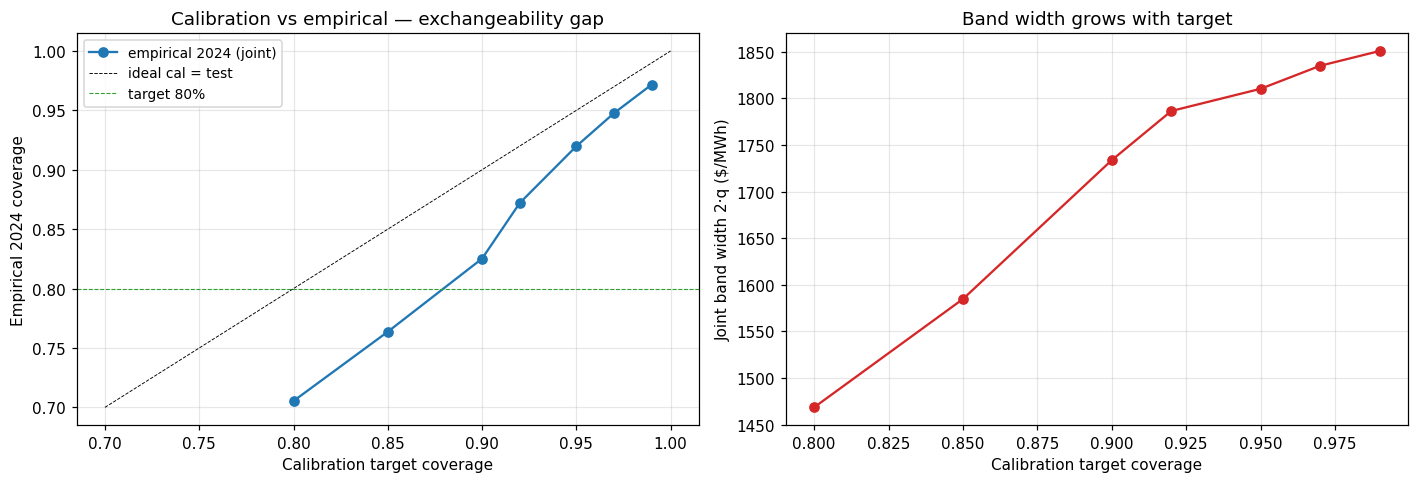

In [3]:
scan_t = SUMMARY['scan_targets']
scan_q = [SUMMARY['scan_qs'][str(c)] if isinstance(list(SUMMARY['scan_qs'].keys())[0], str)
          else SUMMARY['scan_qs'][c] for c in scan_t]
scan_emp = [SUMMARY['scan_empirical_test_coverage'][str(c)] if isinstance(list(SUMMARY['scan_empirical_test_coverage'].keys())[0], str)
            else SUMMARY['scan_empirical_test_coverage'][c] for c in scan_t]
tab = pd.DataFrame({'cal_target': scan_t, 'q ($/MWh)': scan_q,
                    'band width 2·q': [2*q for q in scan_q], 'empirical 2024': scan_emp})
print(tab.round(3).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
ax = axes[0]
ax.plot(scan_t, scan_emp, '-o', label='empirical 2024 (joint)')
ax.plot([0.7, 1.0], [0.7, 1.0], 'k--', lw=0.6, label='ideal cal = test')
ax.axhline(TARGET, color='C2', lw=0.7, ls='--', label=f'target {TARGET:.0%}')
ax.set_xlabel('Calibration target coverage'); ax.set_ylabel('Empirical 2024 coverage')
ax.set_title('Calibration vs empirical — exchangeability gap'); ax.legend(fontsize=9)
ax = axes[1]
ax.plot(scan_t, [2*q for q in scan_q], '-o', color='C3')
ax.set_xlabel('Calibration target coverage'); ax.set_ylabel('Joint band width 2·q ($/MWh)')
ax.set_title('Band width grows with target')
plt.tight_layout(); plt.show()

## 2 — Plotting helper: band denormalised to real MW

We display the band against the **predicted** curve's total quantity (the only total available at inference time). Each curve (actual, baseline, predicted) is plotted on its own (cumulative_quantity, price) coordinates — no normalisation. Because the three curves have different totals, the actual and baseline staircases may extend slightly past the band's right edge.

In [4]:
def plot_one(r, ax):
    pred_total = r['pred_total_qty']
    qty_band   = TAU * pred_total
    pred_emb   = np.asarray(r['pred_embedding'])
    joint_lo, joint_hi = np.asarray(r['band_lower']), np.asarray(r['band_upper'])
    marg_lo,  marg_hi  = np.asarray(r['marginal_band_lower']), np.asarray(r['marginal_band_upper'])

    # Bands on real MW axis
    ax.fill_between(qty_band, joint_lo, joint_hi, color='C1', alpha=0.12,
                    label='joint 80 % band')
    ax.fill_between(qty_band, marg_lo, marg_hi, color='C0', alpha=0.28,
                    label='marginal 80 % band')

    # Actual curve (real staircase)
    ax.step(r['true_curve_qty'], r['true_curve_price'], where='post',
            color='black', lw=1.4, label='actual')
    # Baseline lag-30 curve
    ax.step(r['baseline_curve_qty'], r['baseline_curve_price'], where='post',
            color='C3', lw=1.1, alpha=0.85, label='lag-30 baseline')
    # Exp5 point forecast (the retrieved staircase)
    ax.step(r['pred_curve_qty'], r['pred_curve_price'], where='post',
            color='C0', lw=1.1, alpha=0.85, label='Exp5 point')

    ax.set_xlabel('cumulative quantity (MW)', fontsize=8)
    ax.set_ylabel('price ($/MWh)', fontsize=8)
    ax.tick_params(labelsize=7)


def plot_grid(sample, title=None, ncols=4):
    n = len(sample); nrows = int(np.ceil(n / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(4.5 * ncols, 3.4 * nrows))
    axes = np.atleast_1d(axes).flatten()
    for ax, (_, r) in zip(axes, sample.iterrows()):
        plot_one(r, ax)
        d = pd.Timestamp(r['Trading Date']).strftime('%Y-%m-%d')
        ax.set_title(f'{d} i{int(r["Interval Number"])}  '
                     f'joint={bool(r["joint_inside"])}  marg={100*r["marg_frac"]:.0f}%',
                     fontsize=9)
        if ax is axes[0]:
            ax.legend(fontsize=6.5, loc='best')
    for k in range(len(sample), len(axes)):
        axes[k].axis('off')
    if title:
        fig.suptitle(title, y=1.005, fontsize=12)
    plt.tight_layout(); plt.show()

## 3 — 16 random test auctions with both bands

Re-run this cell for a fresh sample. All curves on real MW × $/MWh axes.

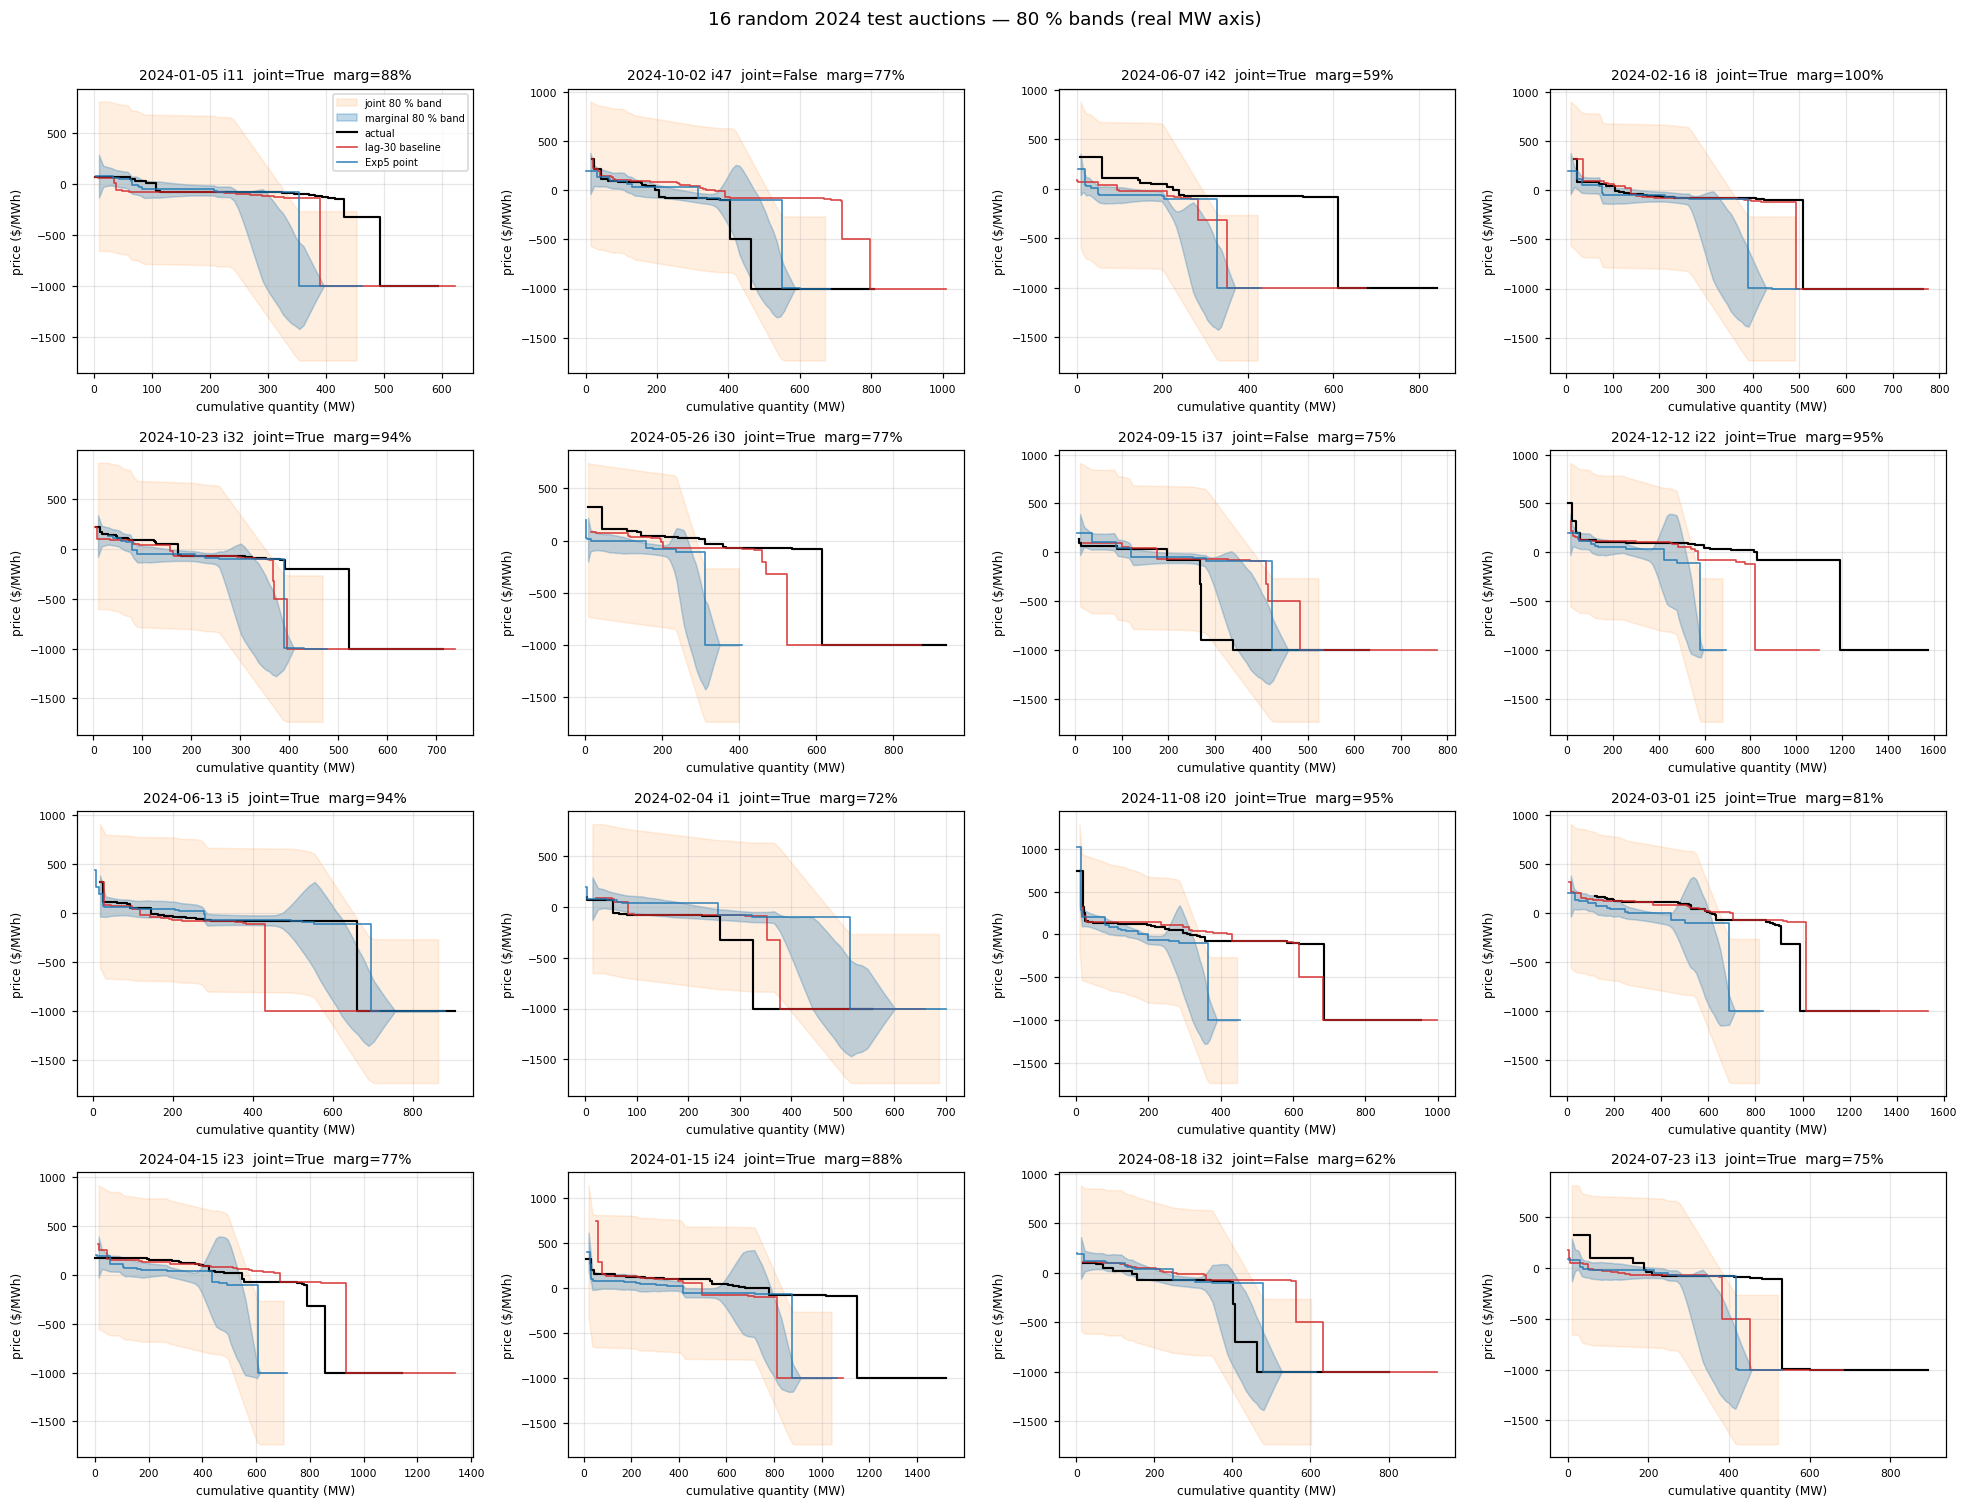

In [5]:
rng = np.random.default_rng()
sample = PREDS.sample(16, random_state=rng.integers(1_000_000)).reset_index(drop=True)
plot_grid(sample, '16 random 2024 test auctions — 80 % bands (real MW axis)')

## 4 — Worst-covered examples

The 12 test rows where the marginal band covered the *least* of the true curve. These are the failure cases.

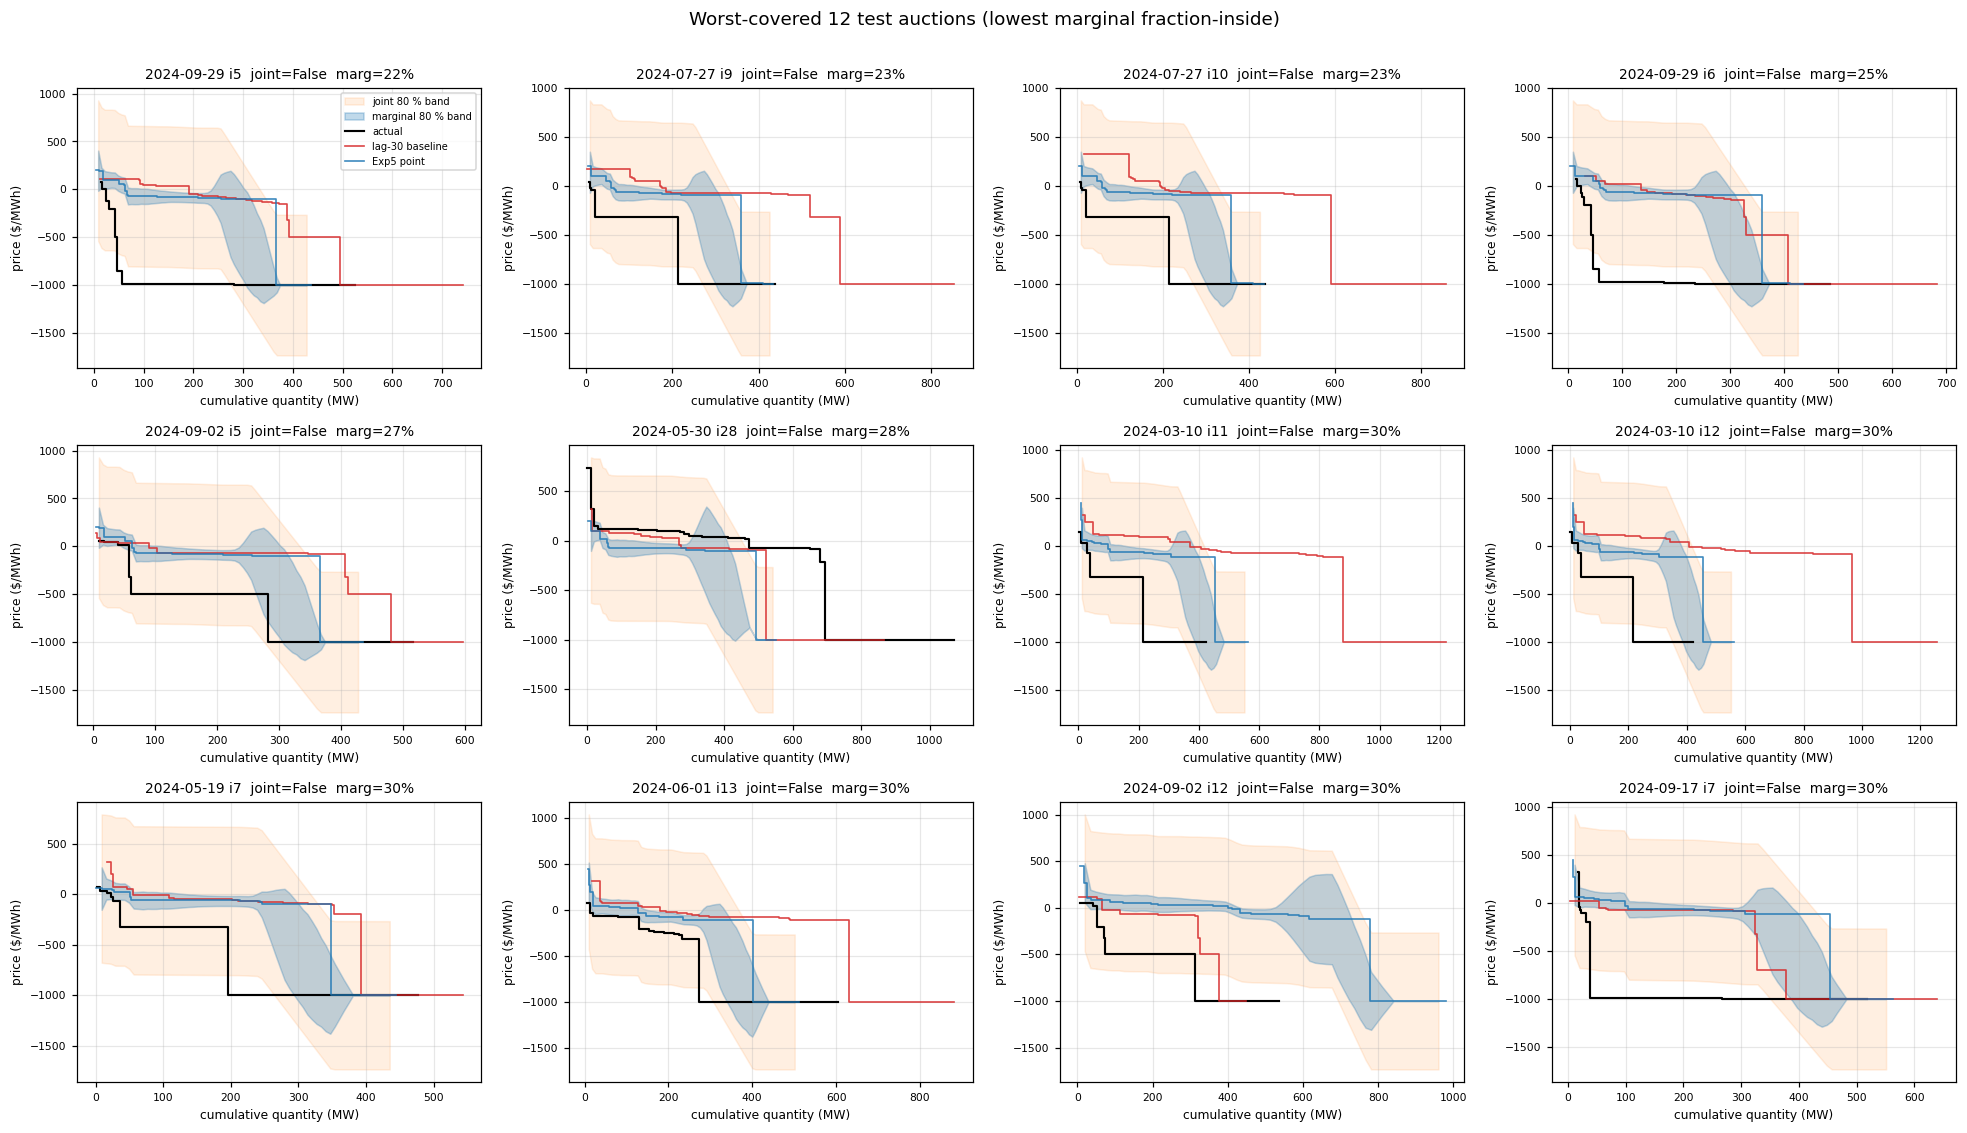

Trading Date  Interval Number  joint_inside  marg_frac  pred_total_qty  true_total_qty  baseline_total_qty
  2024-09-29                5         False      0.219         436.280         525.207             741.413
  2024-07-27                9         False      0.234         434.112         437.737             854.109
  2024-07-27               10         False      0.234         434.112         437.989             858.290
  2024-09-29                6         False      0.250         434.112         484.291             684.033
  2024-09-02                5         False      0.266         436.280         517.118             596.856
  2024-05-30               28         False      0.281         552.408        1072.005             867.411
  2024-03-10               11         False      0.297         562.514         421.947            1219.850
  2024-03-10               12         False      0.297         562.514         422.349            1258.517
  2024-05-19                7        

In [6]:
worst = PREDS.nsmallest(12, 'marg_frac').reset_index(drop=True)
plot_grid(worst, 'Worst-covered 12 test auctions (lowest marginal fraction-inside)', ncols=4)
print(worst[['Trading Date', 'Interval Number', 'joint_inside', 'marg_frac',
             'pred_total_qty', 'true_total_qty', 'baseline_total_qty']]
      .round(3).to_string(index=False))

## 5 — Best-covered examples (sanity check)

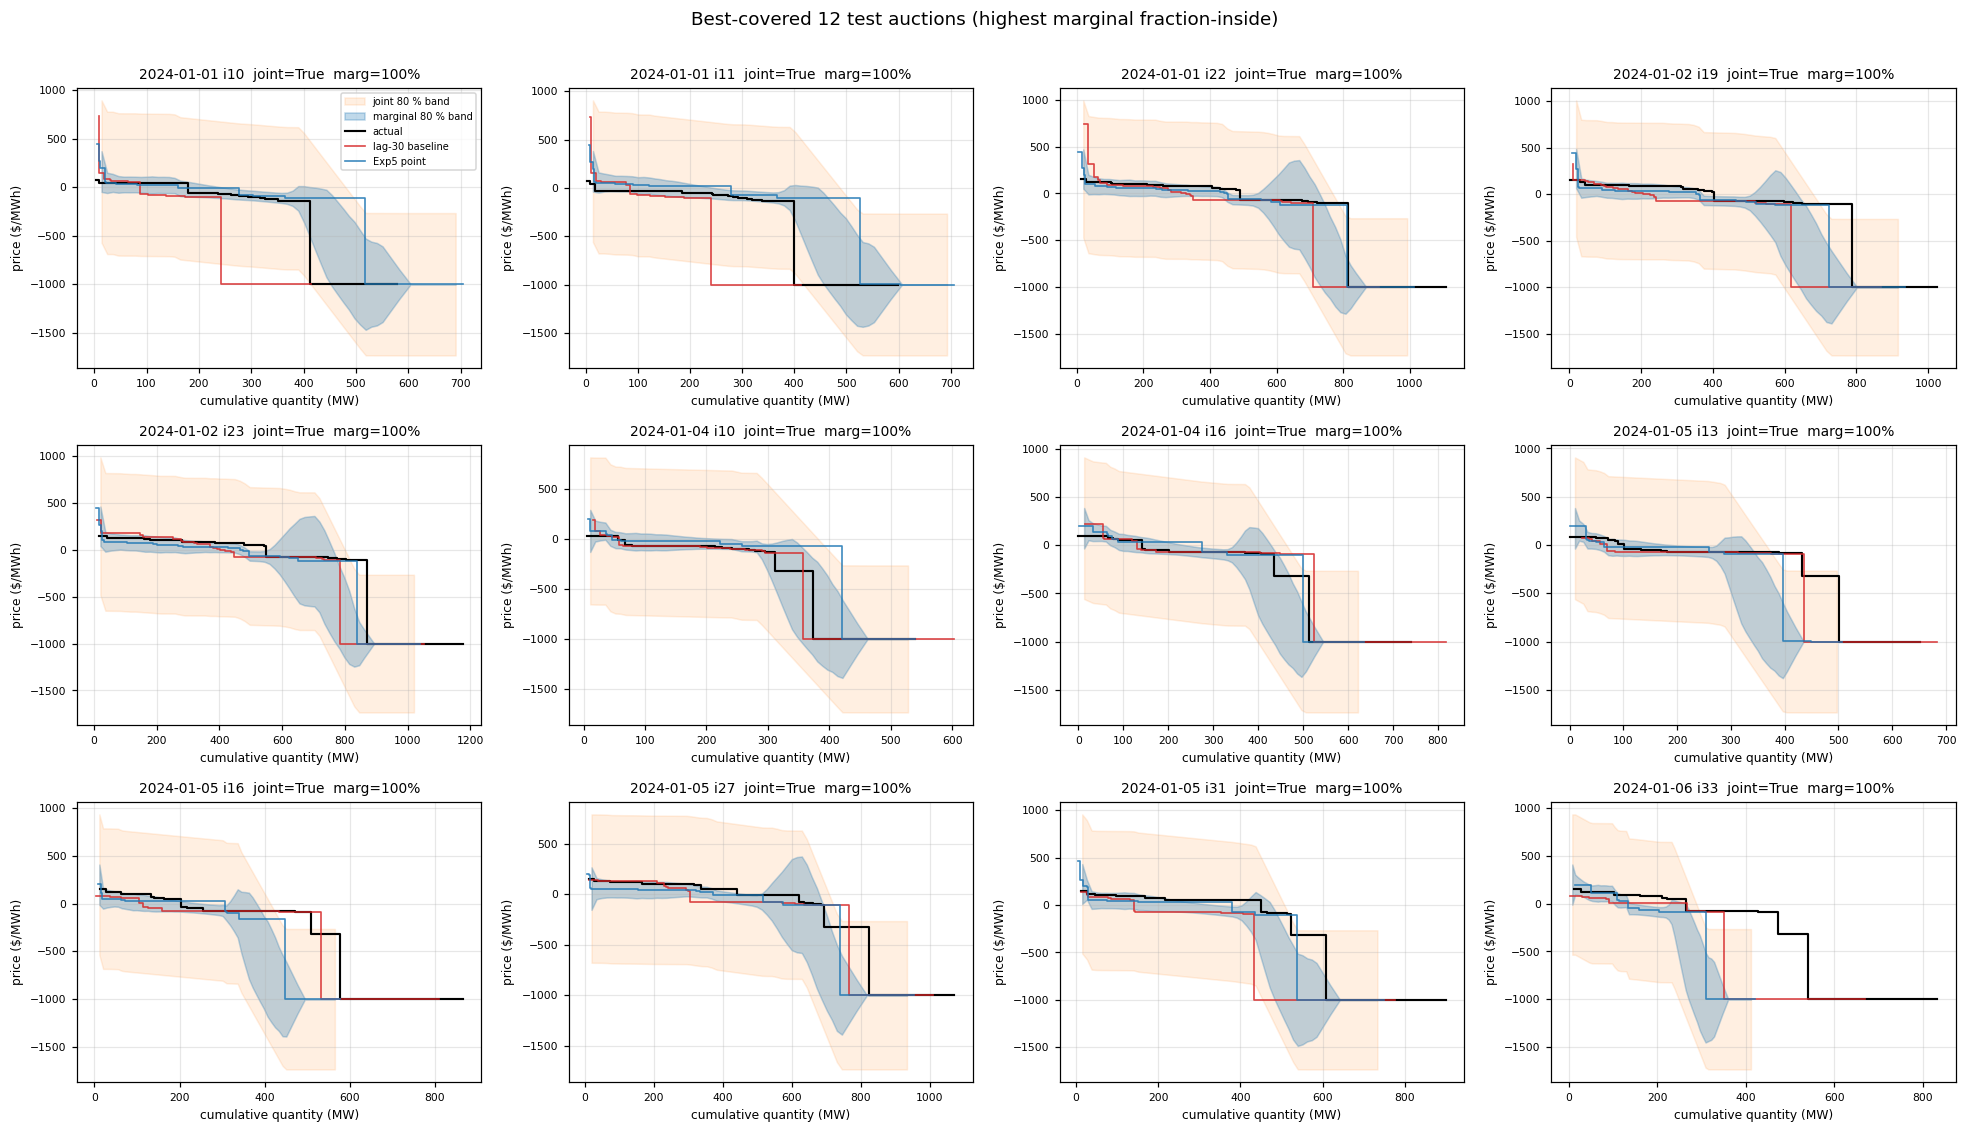

In [7]:
best = PREDS.nlargest(12, 'marg_frac').reset_index(drop=True)
plot_grid(best, 'Best-covered 12 test auctions (highest marginal fraction-inside)', ncols=4)

## 6 — Single auction, large detail view

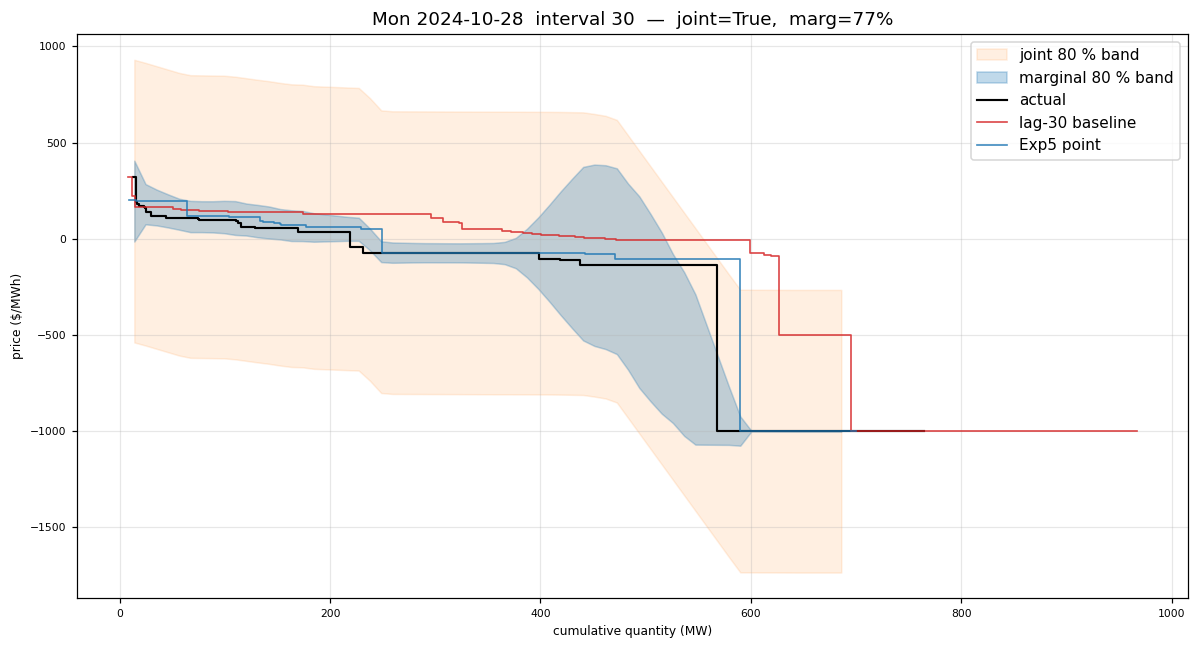

Predicted total qty: 700 MW
Actual total qty   : 765 MW
Baseline total qty : 967 MW


In [8]:
rng = np.random.default_rng()
r = PREDS.sample(1, random_state=rng.integers(1_000_000)).iloc[0]
fig, ax = plt.subplots(figsize=(11, 6))
plot_one(r, ax)
ax.set_xlabel('cumulative quantity (MW)')
ax.set_ylabel('price ($/MWh)')
date_str = pd.Timestamp(r['Trading Date']).strftime('%a %Y-%m-%d')
ax.set_title(f'{date_str}  interval {int(r["Interval Number"])}  —  '
             f'joint={bool(r["joint_inside"])},  marg={100*r["marg_frac"]:.0f}%')
ax.legend(loc='best')
plt.tight_layout(); plt.show()
print(f'Predicted total qty: {r["pred_total_qty"]:.0f} MW')
print(f'Actual total qty   : {r["true_total_qty"]:.0f} MW')
print(f'Baseline total qty : {r["baseline_total_qty"]:.0f} MW')

## 7 — Distribution of per-row coverage and monthly stability

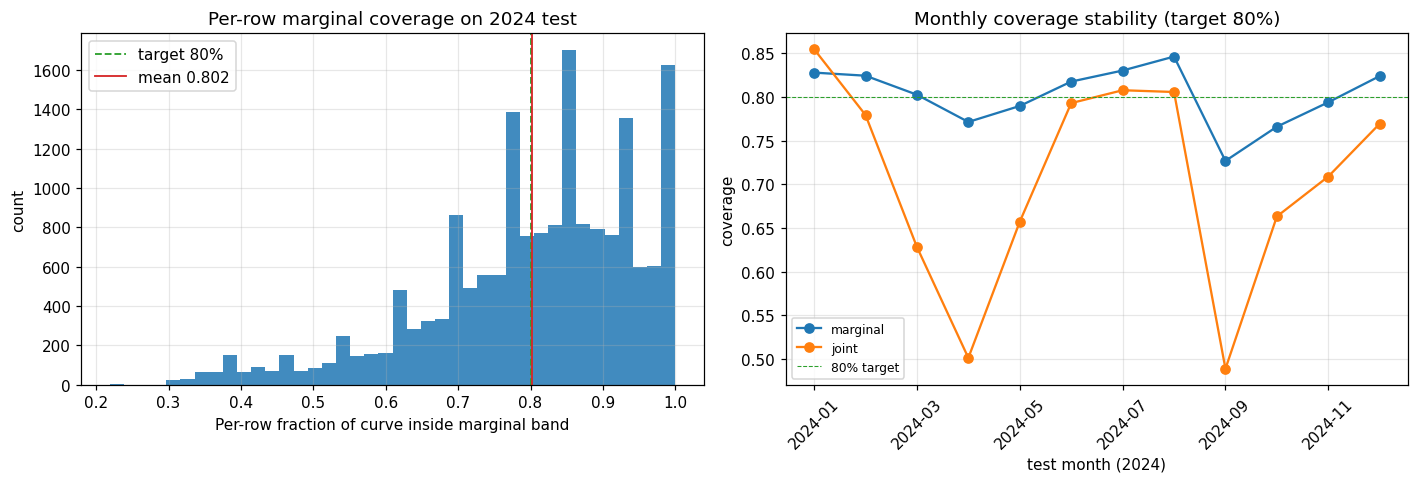

         marg_mean  joint_cov
month                        
2024-01     0.8280     0.8548
2024-02     0.8244     0.7795
2024-03     0.8027     0.6284
2024-04     0.7715     0.5014
2024-05     0.7898     0.6573
2024-06     0.8177     0.7931
2024-07     0.8304     0.8078
2024-08     0.8463     0.8058
2024-09     0.7269     0.4889
2024-10     0.7661     0.6633
2024-11     0.7940     0.7090
2024-12     0.8241     0.7695


In [9]:
PREDS['month'] = PREDS['Trading Date'].dt.to_period('M').astype(str)
monthly = PREDS.groupby('month').agg(
    marg_mean=('marg_frac', 'mean'),
    joint_cov=('joint_inside', 'mean'),
)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
ax = axes[0]
ax.hist(PREDS['marg_frac'], bins=40, color='C0', alpha=0.85)
ax.axvline(TARGET, color='C2', lw=1.2, ls='--', label=f'target {TARGET:.0%}')
ax.axvline(PREDS['marg_frac'].mean(), color='C3', lw=1.2,
           label=f'mean {PREDS["marg_frac"].mean():.3f}')
ax.set_xlabel('Per-row fraction of curve inside marginal band')
ax.set_ylabel('count'); ax.set_title('Per-row marginal coverage on 2024 test'); ax.legend()
ax = axes[1]
monthly.plot(ax=ax, marker='o', linewidth=1.5)
ax.axhline(TARGET, color='C2', lw=0.7, ls='--')
ax.set_xlabel('test month (2024)'); ax.set_ylabel('coverage')
ax.set_title(f'Monthly coverage stability (target {TARGET:.0%})')
ax.legend(['marginal', 'joint', f'{TARGET:.0%} target'], fontsize=8)
plt.xticks(rotation=45); plt.tight_layout(); plt.show()
print(monthly.round(4))

## 8 — Per-interval coverage

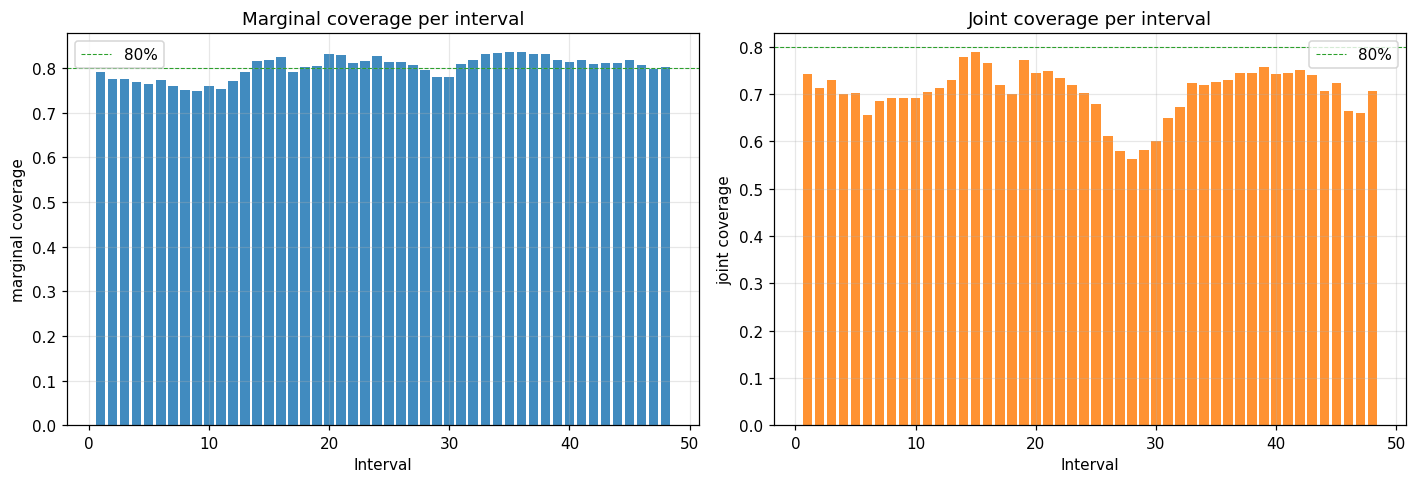

Intervals with the worst marginal coverage:
                 marg_cov  joint_cov    n
Interval Number                          
9                  0.7481     0.6913  366
8                  0.7506     0.6913  366
11                 0.7531     0.7049  366
10                 0.7605     0.6913  366
7                  0.7608     0.6858  366


In [10]:
by_interval = PREDS.groupby('Interval Number').agg(
    marg_cov=('marg_frac', 'mean'),
    joint_cov=('joint_inside', 'mean'),
    n=('marg_frac', 'size'),
)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
ax = axes[0]
ax.bar(by_interval.index, by_interval['marg_cov'], color='C0', alpha=0.85)
ax.axhline(TARGET, color='C2', lw=0.7, ls='--', label=f'{TARGET:.0%}')
ax.set_xlabel('Interval'); ax.set_ylabel('marginal coverage')
ax.set_title(f'Marginal coverage per interval'); ax.legend()
ax = axes[1]
ax.bar(by_interval.index, by_interval['joint_cov'], color='C1', alpha=0.85)
ax.axhline(TARGET, color='C2', lw=0.7, ls='--', label=f'{TARGET:.0%}')
ax.set_xlabel('Interval'); ax.set_ylabel('joint coverage')
ax.set_title(f'Joint coverage per interval'); ax.legend()
plt.tight_layout(); plt.show()
print('Intervals with the worst marginal coverage:')
print(by_interval.sort_values('marg_cov').head(5).round(4))

## 9 — Inference recipe

```python
import numpy as np
from aemo_curves.config import DEFAULT_QUANTITY_GRID    # τ-grid in [0.02, 0.98]
from aemo_curves.models.fof_snap import FoFSnapPredictor

# 1. Once: train Exp5 on train_fit and compute per-τ q on cal at α=0.20
model = FoFSnapPredictor(n_components=10, alpha=100.0, lags=(30, 31, 37))
model.fit(train_fit)
cal_preds = model.predict(cal, historical)
TRUE_CAL = np.vstack(cal_preds['true_embedding'])
PRED_CAL = np.vstack(cal_preds['pred_embedding'])
alpha = 0.20            # → 80 % target
per_tau_q = np.quantile(np.abs(TRUE_CAL - PRED_CAL), 1 - alpha, axis=0)   # shape (64,)

# 2. At inference: predict + denormalise to real MW
preds = model.predict(test_row, historical)
pred_emb       = np.asarray(preds['pred_embedding'].iloc[0])           # shape (64,)
pred_total_qty = float(np.asarray(preds['pred_curve_qty'].iloc[0])[-1])

# Band on REAL cumulative quantity in MW
band_qty       = DEFAULT_QUANTITY_GRID * pred_total_qty                # shape (64,)
band_lower     = pred_emb - per_tau_q                                  # shape (64,)
band_upper     = pred_emb + per_tau_q
```

Implementation: [`experiments/proposals_top5/exp5c_conformal_band.py`](../experiments/proposals_top5/exp5c_conformal_band.py).
Re-run with `--alpha 0.20`.